# Regresión lineal II: estandarización y regularización

**Sesión 9 · Regresión II**

En la sesión 09 ajustamos una regresión lineal múltiple para predecir el precio mediano de la vivienda en los bloques censales de California, y dejamos una pregunta abierta: **si `Population` tiene un coeficiente de 0,000036 y `Latitude`, de −0,44, ¿qué variable es más importante para el modelo?**

Esta sesión tiene dos partes:

+ **Estandarización.** Respondemos a la pregunta poniendo todas las variables en la misma escala, y vemos qué cuentan (y qué no) los coeficientes estandarizados.
+ **Regularización.** Cuando las variables están correlacionadas o el modelo tiene demasiada capacidad, los coeficientes de OLS pueden ser inestables y el modelo puede sobreajustar. **Ridge** y **Lasso** penalizan los coeficientes grandes para controlarlo, y la estandarización es imprescindible para aplicarlas.

**Contenido**

1. Los datos: los mismos de la sesión 08
2. El problema de las escalas
3. Estandarizar las variables
4. Abrir la caja: una predicción comparada con la de un bloque medio
5. Multicolinealidad e inestabilidad
6. Ridge (regularización L2)
7. Lasso (regularización L1)
8. Comparación final: ¿cuándo regularizar?
9. Conclusiones

## 1. Los datos: los mismos de la sesión 08

Repetimos la carga, la limpieza y la división de la sesión 08, con las mismas decisiones: **conservamos los bloques censurados** en el precio máximo y eliminamos los bloques con `AveOccup > 10` o `AveRooms > 15`. Con la misma semilla, la división en entrenamiento y test es exactamente la misma, así que el modelo OLS de hoy es el mismo que el de la sesión anterior.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import Lasso, LinearRegression, Ridge, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

plt.style.use('ggplot')
pd.set_option('display.float_format', '{:.4f}'.format)
SEED = 42                                # la misma semilla que en la sesión 09
rng = np.random.default_rng(SEED)        # para las submuestras de la sección 5

# Colores del curso
C1 = '#2a78d6'       # azul: serie principal, efectos positivos
C2 = '#eb6834'       # naranja: contraste, efectos negativos
C3 = '#898781'       # gris: referencia
CTEXT = '#52514e'    # texto de los ejes

In [2]:
raw = fetch_california_housing(as_frame=True)
TARGET = 'MedHouseVal'

df = raw.frame.copy()
df = df[df['AveOccup'] <= 10]        # misma limpieza que en la sesión 09:
df = df[df['AveRooms'] <= 15]        # conservamos los bloques censurados

FEATURES = [c for c in df.columns if c != TARGET]
X, y = df[FEATURES], df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f'Entrenamiento: {X_train.shape[0]:,} filas · Test: {X_test.shape[0]:,} filas')

Entrenamiento: 16,396 filas · Test: 4,099 filas


## 2. El problema de las escalas

Volvemos a ajustar el modelo OLS con las variables en su escala original. Añadimos a la tabla el **rango** de cada variable en el conjunto de entrenamiento y el producto coeficiente × rango (`efecto_en_rango`): cuánto cambiaría la predicción al pasar del valor mínimo al máximo de la variable, sin cambiar las demás.

In [3]:
ols_raw = LinearRegression().fit(X_train, y_train)

coef_raw = pd.Series(ols_raw.coef_, index=FEATURES, name='coeficiente')
rango = X_train.max() - X_train.min()

tabla_raw = pd.DataFrame({
    'coeficiente': coef_raw.round(6),
    'rango_variable': rango.round(2),
    'efecto_en_rango': (coef_raw * rango).round(4),
})
tabla_raw.sort_values('coeficiente', key=abs, ascending=False)

,coeficiente,rango_variable,efecto_en_rango
AveBedrms,0.8364,3.3800,2.8295
Latitude,-0.4395,9.4100,-4.1356
Longitude,-0.4309,10.0400,-4.3267
MedInc,0.4291,14.5000,6.2216
AveOccup,-0.3430,9.1500,-3.1388
AveRooms,-0.1082,14.0100,-1.5151
HouseAge,0.0106,51.0000,0.5390
Population,0.0000,35679.0000,1.2878


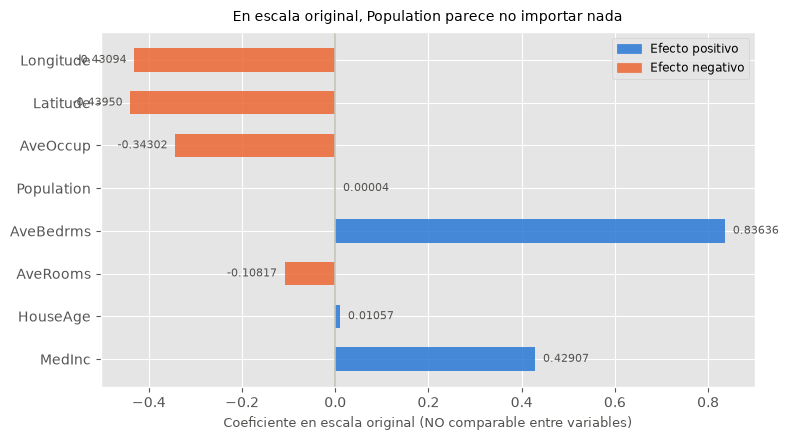

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colores = [C1 if v > 0 else C2 for v in coef_raw]
barras = ax.barh(coef_raw.index, coef_raw.values, color=colores, height=0.55, alpha=0.85)
ax.axvline(0, color='#c3c2b7', linewidth=1.2)
for barra, val in zip(barras, coef_raw.values):
    offset = max(abs(coef_raw)) * 0.02
    ax.text(val + (offset if val >= 0 else -offset), barra.get_y() + barra.get_height() / 2,
            f'{val:.5f}', va='center', ha='left' if val >= 0 else 'right', fontsize=8, color=CTEXT)
ax.set_xlabel('Coeficiente en escala original (NO comparable entre variables)', fontsize=9, color=CTEXT)
ax.set_title('En escala original, Population parece no importar nada', fontsize=10, pad=8)
leyenda = [mpatches.Patch(color=C1, alpha=0.85, label='Efecto positivo'),
           mpatches.Patch(color=C2, alpha=0.85, label='Efecto negativo')]
ax.legend(handles=leyenda, fontsize=8.5)
plt.tight_layout()
plt.show()

**Observaciones**

Cada coeficiente es el cambio en `MedHouseVal` (en cientos de miles de USD) por cada **unidad** que aumenta su variable, sin cambiar las demás. Pero las unidades son muy distintas:

| Variable | Unidad | Coeficiente |
|---|---|---|
| `AveBedrms` | dormitorios por hogar | +0,84 |
| `MedInc` | decenas de miles de USD de ingreso anual | +0,43 |
| `Latitude` | grados (~111 km hacia el norte) | −0,44 |
| `Population` | personas en el bloque | +0,000036 |

¿Significa esto que `AveBedrms` es lo que más importa y que `Population` no influye? **No.** Los coeficientes son grandes o pequeños según la **escala** de cada variable, no según su importancia: un dormitorio más por hogar es un cambio enorme (casi todos los bloques tienen entre 1 y 1,2), mientras que una persona más en el bloque no es nada.

La columna `efecto_en_rango` es una aproximación más honesta: con ella, `Population` ya no es despreciable (+1,3 entre el bloque menos y el más poblado) y `MedInc` pasa a ser la variable con más efecto. Pero el rango depende de los dos valores más extremos, así que tampoco es una buena medida. La solución es **estandarizar**.

## 3. Estandarizar las variables

**Estandarizar** una variable es restarle su media y dividir por su desviación estándar: es la puntuación $z$ de la sesión 06. Después de estandarizar, todas las variables tienen media 0 y desviación estándar 1, y todos los coeficientes comparten la misma unidad: **el cambio en `MedHouseVal` por cada desviación estándar que aumenta la variable**.

**Regla fundamental:** el `StandardScaler` se ajusta **solo con el conjunto de entrenamiento** (`fit`) y después se aplica (`transform`) al entrenamiento y al test. Si lo ajustáramos también con el test, las medias y desviaciones usarían información de datos que el modelo no debería haber visto: es una **fuga de datos** (*data leakage*).

In [5]:
scaler = StandardScaler().fit(X_train)       # medias y desviaciones, SOLO del entrenamiento
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)


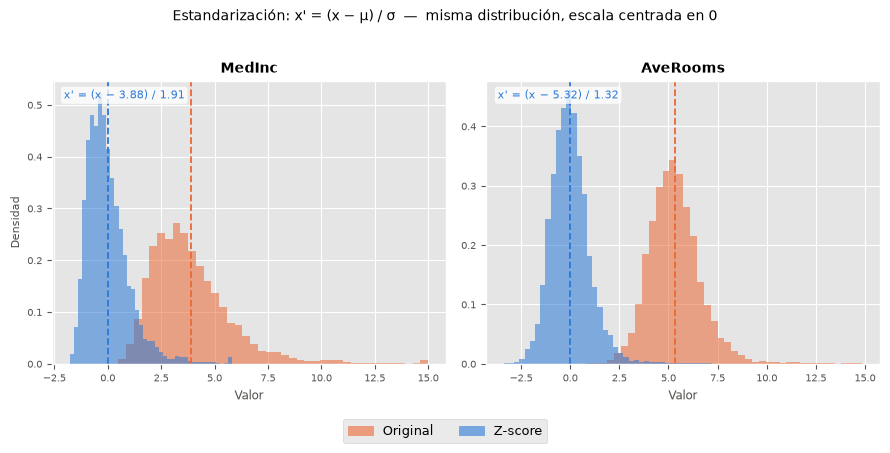

In [6]:
scaler = StandardScaler().fit(X_train)       # medias y desviaciones, SOLO del entrenamiento
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

features_plot = ['MedInc', 'AveRooms']
X_train_sc_df = pd.DataFrame(X_train_sc, columns=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
fig.suptitle("Estandarización: x' = (x − μ) / σ  —  misma distribución, escala centrada en 0",
             fontsize=10, y=1.02)

for ax, feat in zip(axes, features_plot):
    vals    = X_train[feat]
    vals_sc = X_train_sc_df[feat]
    mu, sigma = vals.mean(), vals.std()

    ax.hist(vals,    bins=40, density=True, color=C2, alpha=0.55, label='Original')
    ax.hist(vals_sc, bins=40, density=True, color=C1, alpha=0.55, label='Z-score')

    ax.axvline(mu, color=C2, linewidth=1.3, linestyle='--')
    ax.axvline(0,  color=C1, linewidth=1.3, linestyle='--')

    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_xlabel('Valor', fontsize=8.5, color=CTEXT)
    ax.set_ylabel('Densidad' if feat == features_plot[0] else '', fontsize=8)
    ax.tick_params(labelsize=7.5)

    ax.text(0.03, 0.97,
            f"x' = (x − {mu:.2f}) / {sigma:.2f}",
            transform=ax.transAxes, ha='left', va='top',
            fontsize=8, color=C1,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', alpha=0.8, edgecolor='none'))

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C2, alpha=0.6, label='Original'),
                    Patch(color=C1, alpha=0.6, label='Z-score')],
           loc='lower center', ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

In [7]:
ols_sc = LinearRegression().fit(X_train_sc, y_train)

coef_sc = pd.Series(ols_sc.coef_, index=FEATURES, name='coef_estandarizado')
print(f'Intercepto: {ols_sc.intercept_:.4f} · media de y_train: {y_train.mean():.4f}')
coef_sc.sort_values(key=abs, ascending=False).round(4).to_frame()

Intercepto: 2.0730 · media de y_train: 2.0730


,coef_estandarizado
Latitude,-0.9360
Longitude,-0.8644
MedInc,0.8191
AveOccup,-0.2627
AveRooms,-0.1431
AveBedrms,0.1358
HouseAge,0.1333
Population,0.0414


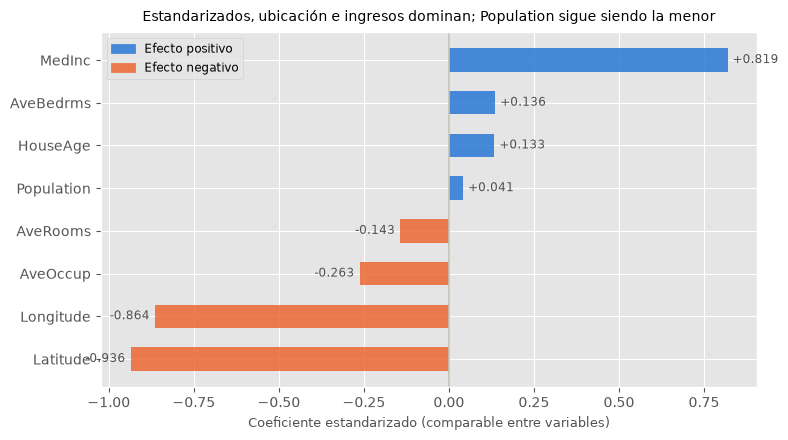

In [8]:
coef_ord = coef_sc.sort_values()
colores = [C1 if v > 0 else C2 for v in coef_ord]

fig, ax = plt.subplots(figsize=(8, 4.5))
barras = ax.barh(coef_ord.index, coef_ord.values, color=colores, height=0.55, alpha=0.85)
ax.axvline(0, color='#c3c2b7', linewidth=1.2)
for barra, val in zip(barras, coef_ord.values):
    ax.text(val + (0.015 if val >= 0 else -0.015), barra.get_y() + barra.get_height() / 2,
            f'{val:+.3f}', va='center', ha='left' if val >= 0 else 'right', fontsize=8.5, color=CTEXT)
ax.set_xlabel('Coeficiente estandarizado (comparable entre variables)', fontsize=9, color=CTEXT)
ax.set_title('Estandarizados, ubicación e ingresos dominan; Population sigue siendo la menor', fontsize=10, pad=8)
leyenda = [mpatches.Patch(color=C1, alpha=0.85, label='Efecto positivo'),
           mpatches.Patch(color=C2, alpha=0.85, label='Efecto negativo')]
ax.legend(handles=leyenda, fontsize=8.5)
plt.tight_layout()
plt.show()

**Observaciones**

- Ahora los coeficientes son comparables. Los tres mayores en valor absoluto son `Latitude` (−0,94), `Longitude` (−0,86) y `MedInc` (+0,82). Les siguen `AveOccup`, `AveRooms`, `AveBedrms` y `HouseAge`, entre 0,13 y 0,26.
- **`MedInc`:** la desviación estándar del ingreso mediano en el entrenamiento es de unos 1,9 (19.000 USD anuales). Un bloque con un ingreso 19.000 USD por encima de la media, con las demás variables iguales, tiene un precio predicho unos 82.000 USD más alto.
- **`Population`:** su coeficiente estandarizado (0,04) sigue siendo el menor. Pero ya no es por su escala: con las variables en la misma unidad, su señal es realmente débil. Esta es la respuesta a la pregunta abierta de la sesión 08: `Latitude` importa mucho más que `Population`.
- **`AveBedrms`:** el coeficiente más grande en escala original (0,84) pasa a ser de los pequeños (0,14).
- El **intercepto** es ahora exactamente la media de `y_train`: es la predicción para un bloque «medio», con todas las variables en su media ($z = 0$).

¿Significa esto que la ubicación es lo más importante del modelo? **Cuidado**: los coeficientes de `Latitude` y `Longitude` son grandes y del mismo signo, pero las dos variables están muy correlacionadas, y sus efectos se compensan en parte. Lo vemos en las secciones 4 y 5.

**Ejercicio 1**

Comprueba que el coeficiente estandarizado de cada variable es su coeficiente en escala original multiplicado por su desviación estándar en el entrenamiento: $\beta_j^{est} = \beta_j \cdot s_j$.

Pista: `StandardScaler` guarda las desviaciones en `scaler.scale_`. Fíjate en que divide entre $n$ y no entre $n-1$ (sesión 06).

In [9]:
# Escribe aquí tu solución

_Tu respuesta:_

### 3.1 Métricas idénticas, coeficientes distintos

La estandarización cambia la representación interna del modelo, pero **no cambia las predicciones ni las métricas**: los dos modelos son matemáticamente equivalentes.

In [10]:
def metricas(y_true, y_pred, nombre: str) -> dict:
    return {
        'Modelo': nombre,
        'R2': round(r2_score(y_true, y_pred), 5),
        'MAE': round(mean_absolute_error(y_true, y_pred), 5),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 5),
    }


y_pred_raw = ols_raw.predict(X_test)
y_pred_sc = ols_sc.predict(X_test_sc)

tabla = pd.DataFrame([
    metricas(y_test, y_pred_raw, 'OLS sin estandarizar'),
    metricas(y_test, y_pred_sc, 'OLS estandarizado'),
]).set_index('Modelo')
display(tabla)
print(f'Máxima diferencia entre las predicciones: {np.abs(y_pred_raw - y_pred_sc).max():.2e}')

,R2,MAE,RMSE
Modelo,,,
OLS sin estandarizar,0.6514,0.4964,0.6789
OLS estandarizado,0.6514,0.4964,0.6789


Máxima diferencia entre las predicciones: 3.53e-13


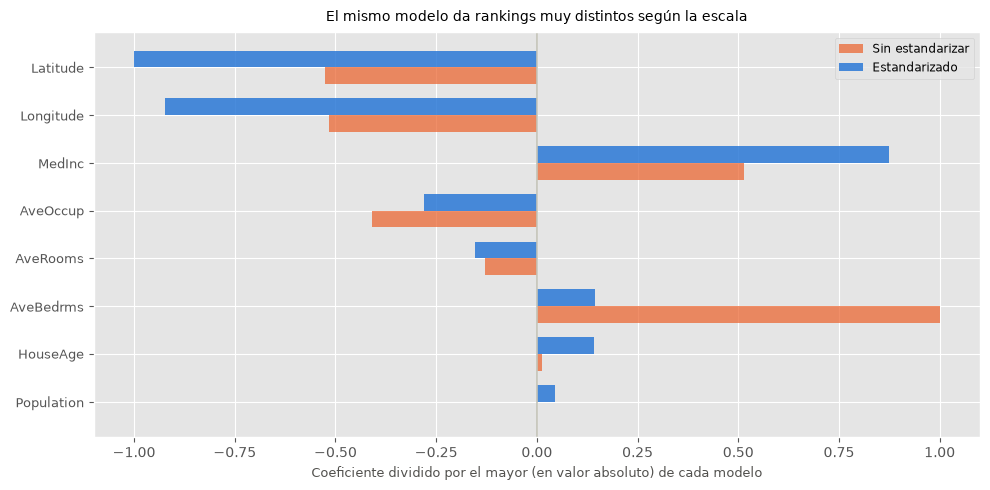

In [11]:
# Coeficientes divididos por el mayor en valor absoluto de cada modelo, para compararlos en un mismo gráfico
coef_raw_norm = coef_raw / coef_raw.abs().max()
coef_sc_norm = coef_sc / coef_sc.abs().max()
orden = coef_sc.abs().sort_values(ascending=True).index
x, w = np.arange(len(FEATURES)), 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(x - w / 2, coef_raw_norm[orden], height=w, color=C2, alpha=0.75, label='Sin estandarizar')
ax.barh(x + w / 2, coef_sc_norm[orden], height=w, color=C1, alpha=0.85, label='Estandarizado')
ax.axvline(0, color='#c3c2b7', linewidth=1.2)
ax.set_yticks(x)
ax.set_yticklabels(orden, fontsize=9)
ax.set_xlabel('Coeficiente dividido por el mayor (en valor absoluto) de cada modelo', fontsize=9, color=CTEXT)
ax.set_title('El mismo modelo da rankings muy distintos según la escala', fontsize=10, pad=8)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

**Observaciones**

- **Para predecir**, estandarizar o no es indiferente: las métricas y las predicciones son idénticas.
- **Para interpretar** los coeficientes, la estandarización es imprescindible: sin ella, el ranking lo decide la escala de cada variable.
- **Para regularizar** (a partir de la sección 5), también es imprescindible. Ridge y Lasso penalizan todos los coeficientes por igual. Sin estandarizar, una variable con escala pequeña (como `AveBedrms`) necesita un coeficiente grande y la penalización la castiga mucho, mientras que una variable con escala grande (como `Population`) tiene un coeficiente diminuto y la penalización apenas la toca.

## 4. Abrir la caja: una predicción comparada con la de un bloque medio

En la sesión 09 descompusimos una predicción en contribuciones $\beta_j x_j$, y vimos que las de `Latitude` y `Longitude` eran enormes por sus unidades (+52 y −17) y se compensaban con el intercepto. Con las variables estandarizadas, la descomposición es mucho más útil:

$$\hat{y} = \underbrace{\bar{y}_{\text{train}}}_{\text{bloque medio}} + \sum_j \beta_j^{est} z_j$$

Cada término $\beta_j^{est} z_j$ dice **cuánto se separa la predicción de la de un bloque medio por culpa de la variable $j$**. Es la comparación con un bloque típico que echábamos de menos en la sesión 08, y es la idea en la que se basan métodos de explicabilidad como SHAP, que veremos en el bloque de *machine learning*.

In [12]:
def descomponer_est(i: int) -> pd.DataFrame:
    # Contribución de cada variable a la predicción del bloque i del test, respecto a un bloque medio
    z = pd.Series(X_test_sc[i], index=FEATURES)
    contrib = pd.DataFrame({
        'valor': X_test.iloc[i],
        'z (desv. estándar)': z,
        'coef. estandarizado': coef_sc,
        'contribución': z * coef_sc,
    })
    return contrib.reindex(contrib['contribución'].abs().sort_values(ascending=False).index)


display(descomponer_est(0))
contrib_0 = (X_test_sc[0] * ols_sc.coef_).sum()
print(f'Bloque medio (intercepto):  {ols_sc.intercept_:.4f}')
print(f'+ suma de contribuciones:   {contrib_0:+.4f}')
print(f'= predicción:               {ols_sc.intercept_ + contrib_0:.4f}  (model.predict: {y_pred_sc[0]:.4f})')
print(f'Valor real:                 {y_test.iloc[0]:.4f}')

,valor,z (desv. estándar),coef. estandarizado,contribución
Latitude,38.5800,1.3879,-0.9360,-1.2991
Longitude,-121.3000,-0.8594,-0.8644,0.7429
MedInc,2.8966,-0.5156,0.8191,-0.4223
AveOccup,3.0838,0.2086,-0.2627,-0.0548
AveRooms,5.2343,-0.0635,-0.1431,0.0091
Population,1619.0000,0.1629,0.0414,0.0067
HouseAge,29.0000,0.0237,0.1333,0.0032
AveBedrms,1.0724,-0.0053,0.1358,-0.0007


Bloque medio (intercepto):  2.0730
+ suma de contribuciones:   -1.0151
= predicción:               1.0579  (model.predict: 1.0579)
Valor real:                 0.9240


Este es el mismo bloque que descompusimos en la sesión 08, con la misma predicción. Ahora las contribuciones tienen un tamaño razonable y se leen directamente: el bloque está en el norte (latitud 38,6, casi 1,4 desviaciones estándar por encima de la media), y eso baja su precio predicho; sus ingresos están por debajo de la media, y eso también lo baja; su longitud lo sube.

**Cuándo puede engañar esta explicación.** Las contribuciones de `Latitude` y `Longitude` suelen ser grandes y de signo contrario. El modelo no «piensa» en latitud y longitud por separado: como las dos variables están muy correlacionadas (California es una franja diagonal), lo que mide de verdad es la combinación de las dos, la distancia a la costa sur. Leer cada contribución por separado, como si pudiéramos mover la latitud sin mover la longitud, puede llevar a conclusiones sin sentido.

**Ejercicio 2**

Una forma sencilla de medir la **importancia global** de cada variable es la media del valor absoluto de su contribución en todos los bloques del test: $\frac{1}{n}\sum_i |\beta_j^{est} z_{ij}|$.

a) Calcúlala y ordena las variables de mayor a menor.

b) Compara el ranking con el de los coeficientes estandarizados. ¿Coinciden? ¿Por qué deberían parecerse?

c) ¿Te fías de que `Latitude` sea la variable más importante del modelo? Piensa en lo que hemos dicho sobre las contribuciones de `Latitude` y `Longitude`.

In [13]:
# Escribe aquí tu solución

_Tu respuesta:_

## 5. Multicolinealidad e inestabilidad

OLS no impone ninguna restricción sobre los coeficientes. Cuando dos variables explicativas están muy correlacionadas (**multicolinealidad**), llevan casi la misma información, y el modelo puede repartir esa señal compartida de formas muy distintas según los datos con los que se entrene. Empezamos por buscar las correlaciones fuertes en el entrenamiento:

Pares con |correlación| > 0,5:


,Variable A,Variable B,Correlación
62,Longitude,Latitude,-0.9277
16,AveRooms,MedInc,0.6283


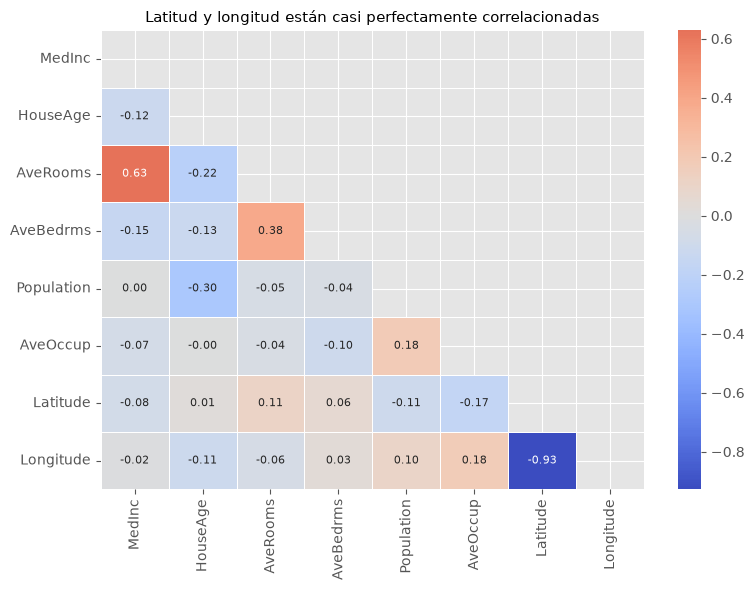

In [14]:
corr = X_train.corr()

print('Pares con |correlación| > 0,5:')
pares = corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().reset_index()
pares.columns = ['Variable A', 'Variable B', 'Correlación']
display(pares[pares['Correlación'].abs() > 0.5].sort_values('Correlación', key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mascara, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax, annot_kws={'size': 8})
ax.set_title('Latitud y longitud están casi perfectamente correlacionadas', fontsize=11)
plt.tight_layout()
plt.show()

Solo hay dos pares con una correlación fuerte: **`Latitude` y `Longitude`** (−0,93), porque California es una franja diagonal y, cuanto más al norte, más al oeste, y **`MedInc` y `AveRooms`** (0,63), porque en los barrios con más ingresos las viviendas son más grandes.

> En los datos originales, `AveRooms` y `AveBedrms` tienen una correlación de 0,85. Tras eliminar los bloques con valores imposibles en los cocientes (sesión 08), baja a 0,39: buena parte de esa correlación la creaban unos pocos bloques atípicos. Es un ejemplo más de por qué hay que mirar los datos antes de calcular una correlación.

¿Hacen inestables los coeficientes estas correlaciones? Para comprobarlo, ajustamos el modelo en 20 submuestras aleatorias del 50 % del entrenamiento y medimos cuánto varía cada coeficiente:

In [15]:
coefs_ols = []
for _ in range(20):
    idx = rng.choice(len(X_train_sc), size=len(X_train_sc) // 2, replace=False)
    m = LinearRegression().fit(X_train_sc[idx], y_train.values[idx])
    coefs_ols.append(m.coef_)
coefs_ols = np.array(coefs_ols)

estabilidad = pd.DataFrame({
    'coef. (todo el entrenamiento)': coef_sc,
    'desv. estándar en submuestras': coefs_ols.std(axis=0),
    'mínimo': coefs_ols.min(axis=0),
    'máximo': coefs_ols.max(axis=0),
}, index=FEATURES)
estabilidad.sort_values('desv. estándar en submuestras', ascending=False).round(4)

,coef. (todo el entrenamiento),desv. estándar en submuestras,mínimo,máximo
Latitude,-0.9360,0.0182,-0.9689,-0.9127
Longitude,-0.8644,0.0164,-0.8976,-0.8431
AveRooms,-0.1431,0.0144,-0.1687,-0.1150
MedInc,0.8191,0.0142,0.7855,0.8444
AveBedrms,0.1358,0.0102,0.1157,0.1567
AveOccup,-0.2627,0.0056,-0.2743,-0.2537
Population,0.0414,0.0049,0.0298,0.0505
HouseAge,0.1333,0.0049,0.1226,0.1454


**Observaciones**

- Los coeficientes que más varían entre submuestras son los de **`Latitude` y `Longitude`**, el par más correlacionado: el modelo reparte entre las dos su señal compartida de forma algo distinta en cada submuestra.
- Aun así, la variación es pequeña: alrededor de 0,02 en coeficientes de casi 0,9. Ningún coeficiente cambia de signo. **Con 16.396 bloques y solo 8 variables, OLS es estable** incluso con multicolinealidad.
- La multicolinealidad es un problema serio cuando hay **pocos datos**, **muchas variables** o correlaciones **casi perfectas**. Lo comprobarás en el ejercicio 3 y en el ejercicio 5.

**Ejercicio 3**

Ajusta el modelo OLS estandarizado **sin `Longitude`**. ¿Qué le pasa al coeficiente de `Latitude`? ¿Y al R² de test? ¿Qué te dice esto sobre cómo interpretar el coeficiente de `Latitude` en el modelo completo?

Pista: `np.delete(X_train_sc, FEATURES.index('Longitude'), axis=1)` quita una columna.

In [16]:
# Escribe aquí tu solución

_Tu respuesta:_

### 5.1 Qué hace la regularización

La **regularización** añade a la función de coste de OLS una **penalización** que desincentiva los coeficientes grandes:

$$\text{Ridge:} \quad \min_\beta \sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j \beta_j^2 \qquad\qquad \text{Lasso:} \quad \min_\beta \sum_i (y_i - \hat{y}_i)^2 + \alpha \sum_j |\beta_j|$$

El **hiperparámetro** $\alpha$ controla la fuerza de la penalización: con $\alpha = 0$ tenemos OLS, y cuanto mayor es $\alpha$, más se encogen los coeficientes hacia 0. Como la penalización trata igual a todos los coeficientes, las variables tienen que estar en la misma escala: **siempre se estandariza antes de regularizar**.

## 6. Ridge (regularización L2)

Ridge penaliza la **suma de los cuadrados** de los coeficientes. Todos se encogen hacia 0, pero ninguno llega exactamente a 0. Es útil con multicolinealidad: en lugar de dar un coeficiente grande a una variable y uno pequeño a otra muy correlacionada, reparte la señal entre las dos.

El **camino de regularización** muestra cómo cambia cada coeficiente al aumentar $\alpha$:

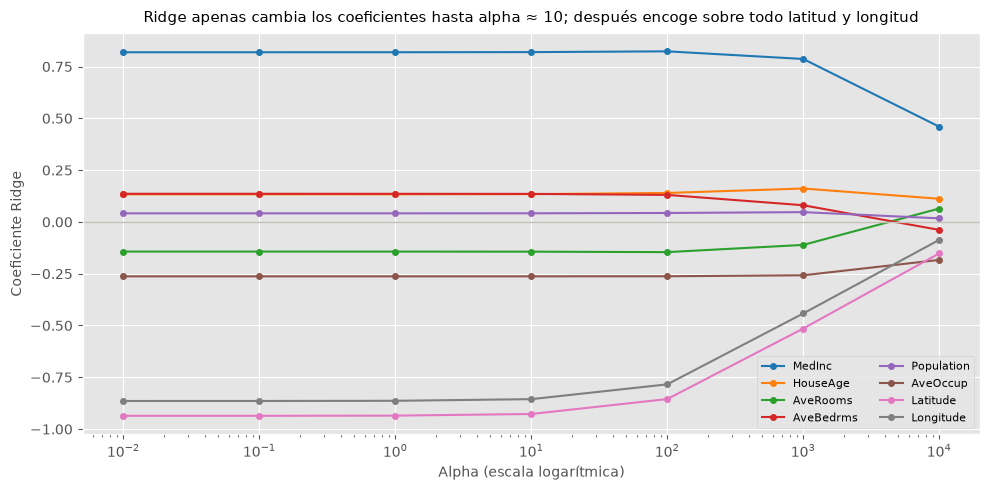

In [17]:
alphas = [0.01, 0.1, 1, 10, 100, 1000, 10000]
coefs_ridge = np.array([Ridge(alpha=a).fit(X_train_sc, y_train).coef_ for a in alphas])

fig, ax = plt.subplots(figsize=(10, 5))
for i, feat in enumerate(FEATURES):
    ax.semilogx(alphas, coefs_ridge[:, i], marker='o', markersize=4, label=feat, linewidth=1.5, color=plt.cm.tab10(i))
ax.axhline(0, color='#c3c2b7', linewidth=1)
ax.set_xlabel('Alpha (escala logarítmica)', fontsize=10, color=CTEXT)
ax.set_ylabel('Coeficiente Ridge', fontsize=10, color=CTEXT)
ax.set_title('Ridge apenas cambia los coeficientes hasta alpha ≈ 10; después encoge sobre todo latitud y longitud', fontsize=11, pad=8)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

¿Qué valor de $\alpha$ elegimos? **Nunca mirando el conjunto de test**: lo elegimos por **validación cruzada** en el entrenamiento. Partimos el entrenamiento en 5 partes; para cada $\alpha$, entrenamos con 4 y evaluamos con la quinta, cinco veces, y promediamos el R².

Para que la validación cruzada sea correcta, la estandarización tiene que hacerse **dentro** de cada partición: el `StandardScaler` se ajusta con las 4 partes de entrenamiento, no con la parte de validación. Por eso metemos el escalador y el modelo en un mismo *pipeline* (`make_pipeline`) y le pasamos a `cross_val_score` los datos **sin estandarizar**.

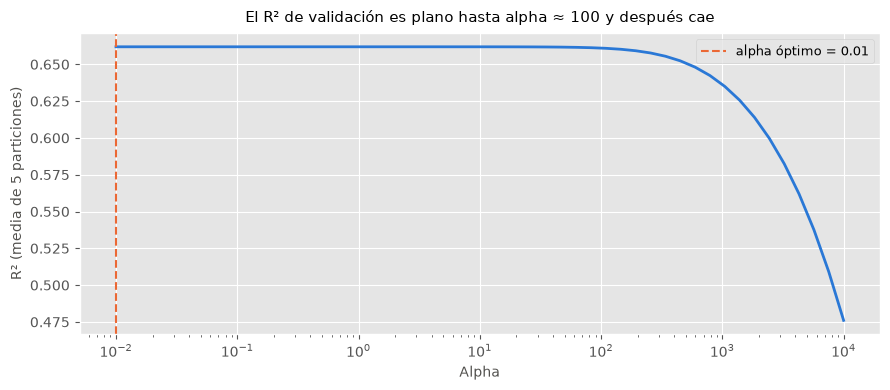

Alpha óptimo de Ridge: 0.0100


In [18]:
alphas_cv = np.logspace(-2, 4, 50)
scores_ridge = [
    cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), X_train, y_train, cv=5, scoring='r2').mean()
    for a in alphas_cv
]
best_alpha_ridge = alphas_cv[np.argmax(scores_ridge)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(alphas_cv, scores_ridge, color=C1, linewidth=2)
ax.axvline(best_alpha_ridge, color=C2, linewidth=1.5, linestyle='--', label=f'alpha óptimo = {best_alpha_ridge:.2f}')
ax.set_xlabel('Alpha', fontsize=10, color=CTEXT)
ax.set_ylabel('R² (media de 5 particiones)', fontsize=10, color=CTEXT)
ax.set_title('El R² de validación es plano hasta alpha ≈ 100 y después cae', fontsize=11, pad=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()
print(f'Alpha óptimo de Ridge: {best_alpha_ridge:.4f}')

In [19]:
ridge = Ridge(alpha=best_alpha_ridge).fit(X_train_sc, y_train)
y_pred_ridge = ridge.predict(X_test_sc)

comp = pd.DataFrame({
    'OLS': ols_sc.coef_,
    'Ridge': ridge.coef_,
    'encogimiento_%': (np.abs(ridge.coef_ - ols_sc.coef_) / np.abs(ols_sc.coef_) * 100).round(3),
}, index=FEATURES)
comp.sort_values('OLS', key=abs, ascending=False)

,OLS,Ridge,encogimiento_%
Latitude,-0.9360,-0.9360,0.0010
Longitude,-0.8644,-0.8644,0.0010
MedInc,0.8191,0.8191,0.0000
AveOccup,-0.2627,-0.2627,0.0000
AveRooms,-0.1431,-0.1431,0.0000
AveBedrms,0.1358,0.1358,0.0000
HouseAge,0.1333,0.1333,0.0010
Population,0.0414,0.0414,0.0000


**Observaciones**

- La validación cruzada elige el $\alpha$ **más pequeño** de la rejilla: el R² de validación es prácticamente el mismo hasta $\alpha \approx 100$ y solo empieza a bajar después. Con este $\alpha$, Ridge encoge los coeficientes menos de un 0,01 %: **Ridge y OLS son, en la práctica, el mismo modelo**.
- No es un fallo: es el resultado esperable con 16.396 bloques y 8 variables. OLS ya es estable (sección 5) y no sobreajusta (sesión 08), así que no hay nada que corregir.
- En el camino de regularización se ve qué haría Ridge con un $\alpha$ grande: a partir de $\alpha \approx 10$ empieza a encoger, antes que nada, los coeficientes de `Latitude` y `Longitude`, las variables más correlacionadas, y con $\alpha$ muy grandes encoge todos los demás, también el de `MedInc`.
- Ridge **no selecciona variables**: ningún coeficiente llega exactamente a 0, ni siquiera con $\alpha = 10.000$.

## 7. Lasso (regularización L1)

Lasso penaliza la **suma de los valores absolutos** de los coeficientes. A diferencia de Ridge, algunos coeficientes pueden llegar **exactamente a 0**: Lasso hace una **selección automática de variables**.

La razón es geométrica. La región de coeficientes que permite la penalización L1 es un rombo, con vértices sobre los ejes (donde algún coeficiente vale 0), y la solución óptima tiende a «caer» en uno de esos vértices. La región de Ridge (L2) es un círculo, sin vértices, y la solución casi nunca cae exactamente sobre un eje.

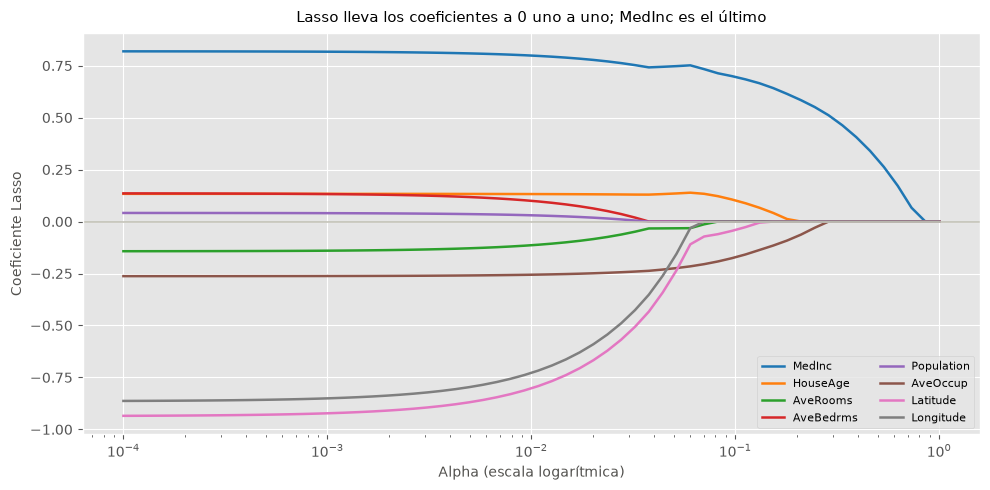

,alpha en el que se anula
AveBedrms,0.0377
Population,0.0377
Longitude,0.0704
AveRooms,0.0823
Latitude,0.1536
HouseAge,0.2099
AveOccup,0.2868
MedInc,0.8555


In [20]:
alphas_lasso = np.logspace(-4, 0, 60)
coefs_lasso = np.array([Lasso(alpha=a, max_iter=5000).fit(X_train_sc, y_train).coef_ for a in alphas_lasso])

fig, ax = plt.subplots(figsize=(10, 5))
for i, feat in enumerate(FEATURES):
    ax.semilogx(alphas_lasso, coefs_lasso[:, i], linewidth=1.8, label=feat, color=plt.cm.tab10(i))
ax.axhline(0, color='#c3c2b7', linewidth=1.2)
ax.set_xlabel('Alpha (escala logarítmica)', fontsize=10, color=CTEXT)
ax.set_ylabel('Coeficiente Lasso', fontsize=10, color=CTEXT)
ax.set_title('Lasso lleva los coeficientes a 0 uno a uno; MedInc es el último', fontsize=11, pad=8)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

# Primer alpha de la rejilla en el que cada coeficiente vale exactamente 0
primer_cero = {f: alphas_lasso[np.argmax(coefs_lasso[:, i] == 0)] for i, f in enumerate(FEATURES)
               if (coefs_lasso[:, i] == 0).any()}
pd.Series(primer_cero, name='alpha en el que se anula').sort_values().to_frame()

**Observaciones**

- Al aumentar $\alpha$, Lasso **anula coeficientes uno a uno**. Los primeros en desaparecer son los de `AveBedrms` y `Population`, las variables con menos señal; el último que sobrevive es el de `MedInc`.
- El orden en que se anulan los coeficientes es otra forma de leer la importancia de las variables, con la misma advertencia de siempre: con variables correlacionadas, como `Latitude` y `Longitude`, Lasso tiende a quedarse con una y a anular la otra, y cuál elige puede depender de detalles de los datos. Fíjate en que `Longitude` se anula bastante antes que `Latitude`.

Elegimos $\alpha$ por validación cruzada, igual que con Ridge:

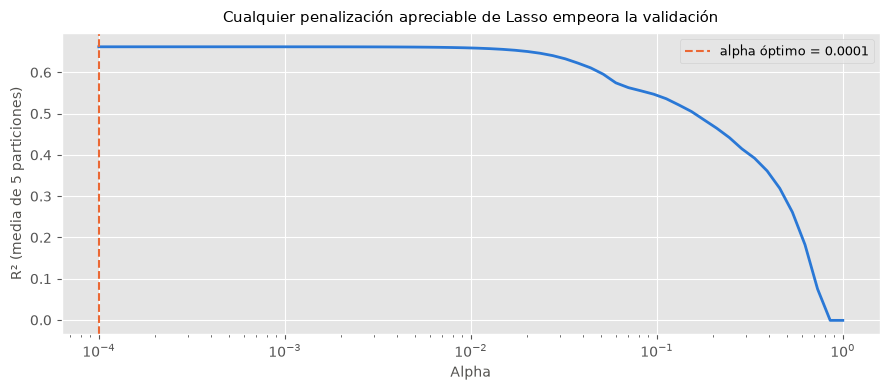

Alpha óptimo de Lasso: 0.000100
Coeficientes anulados: 0 de 8


In [21]:
scores_lasso = [
    cross_val_score(make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=5000)), X_train, y_train,
                    cv=5, scoring='r2').mean()
    for a in alphas_lasso
]
best_alpha_lasso = alphas_lasso[np.argmax(scores_lasso)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(alphas_lasso, scores_lasso, color=C1, linewidth=2)
ax.axvline(best_alpha_lasso, color=C2, linewidth=1.5, linestyle='--', label=f'alpha óptimo = {best_alpha_lasso:.4f}')
ax.set_xlabel('Alpha', fontsize=10, color=CTEXT)
ax.set_ylabel('R² (media de 5 particiones)', fontsize=10, color=CTEXT)
ax.set_title('Cualquier penalización apreciable de Lasso empeora la validación', fontsize=11, pad=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

lasso = Lasso(alpha=best_alpha_lasso, max_iter=5000).fit(X_train_sc, y_train)
y_pred_lasso = lasso.predict(X_test_sc)
print(f'Alpha óptimo de Lasso: {best_alpha_lasso:.6f}')
print(f'Coeficientes anulados: {(lasso.coef_ == 0).sum()} de {len(FEATURES)}')

**Observaciones**

- De nuevo, la validación cruzada elige el $\alpha$ **más pequeño** de la rejilla, y con él Lasso **no anula ningún coeficiente**. Con estos datos, quitar variables siempre empeora un poco la predicción: las 8 aportan algo.
- La selección de variables de Lasso es útil cuando hay **muchas variables y pocas relevantes**, que no es nuestro caso.

### 7.1 Comprueba a la IA

Si le pides a un asistente de IA «usa Lasso para ver qué variables sobran en el modelo del precio de la vivienda», es fácil que te proponga un código como este, con las variables sin estandarizar:

In [22]:
# Código como el que suele proponer un asistente de IA
lasso_ia = Lasso(alpha=0.1).fit(X_train, y_train)
coef_ia = pd.Series(lasso_ia.coef_, index=FEATURES)
print('Variables que se mantienen:', coef_ia[coef_ia != 0].index.tolist())
print('Variables que sobran:      ', coef_ia[coef_ia == 0].index.tolist())

Variables que se mantienen: ['MedInc', 'HouseAge', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Variables que sobran:       ['AveRooms', 'AveBedrms']


**Ejercicio 4**

a) Repite el ajuste con el mismo $\alpha = 0{,}1$ pero con las variables **estandarizadas** (`X_train_sc`). ¿Qué variables se mantienen y cuáles sobran ahora?

b) ¿Por qué el asistente mantiene `Population` y elimina `AveBedrms`? Relaciónalo con lo que vimos en la sección 3.1 sobre la regularización sin estandarizar.



In [23]:
# Escribe aquí tu solución

_Tu respuesta:_

## 8. Comparación final: ¿cuándo regularizar?

,R2,MAE,RMSE
Modelo,,,
OLS (estandarizado),0.6514,0.4964,0.6789
Ridge (alpha=0.01),0.6514,0.4964,0.6789
Lasso (alpha=0.0001),0.6515,0.4964,0.6789


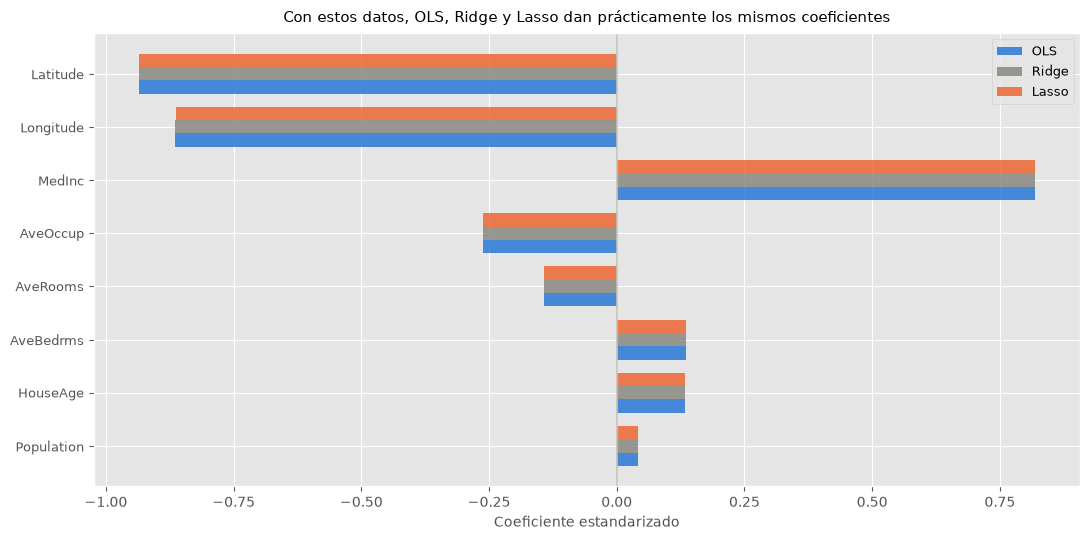

In [24]:
tabla_final = pd.DataFrame([
    metricas(y_test, y_pred_sc, 'OLS (estandarizado)'),
    metricas(y_test, y_pred_ridge, f'Ridge (alpha={best_alpha_ridge:.2f})'),
    metricas(y_test, y_pred_lasso, f'Lasso (alpha={best_alpha_lasso:.4f})'),
]).set_index('Modelo')
display(tabla_final)

orden = coef_sc.abs().sort_values(ascending=True).index
x, w = np.arange(len(FEATURES)), 0.25
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(x - w, [ols_sc.coef_[FEATURES.index(f)] for f in orden], height=w, color=C1, alpha=0.85, label='OLS')
ax.barh(x, [ridge.coef_[FEATURES.index(f)] for f in orden], height=w, color=C3, alpha=0.85, label='Ridge')
ax.barh(x + w, [lasso.coef_[FEATURES.index(f)] for f in orden], height=w, color=C2, alpha=0.85, label='Lasso')
ax.axvline(0, color='#c3c2b7', linewidth=1.2)
ax.set_yticks(x)
ax.set_yticklabels(orden, fontsize=9)
ax.set_xlabel('Coeficiente estandarizado', fontsize=10, color=CTEXT)
ax.set_title('Con estos datos, OLS, Ridge y Lasso dan prácticamente los mismos coeficientes', fontsize=11, pad=8)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

**Observaciones**

Con 8 variables y más de 16.000 bloques de entrenamiento, los tres modelos son prácticamente iguales: mismas métricas y mismos coeficientes. **La regularización no mejora un modelo que no tiene ningún problema que corregir.** Eso no la hace inútil: es imprescindible cuando el modelo tiene mucha capacidad en relación con los datos.

| Situación | Recomendación |
|---|---|
| Muchas variables, pocas relevantes | **Lasso**: selección automática de variables |
| Variables correlacionadas, todas relevantes | **Ridge**: reparte la señal sin eliminar variables |
| Muchos datos, pocas variables, OLS estable | **OLS**: la regularización aporta poco (nuestro caso) |
| Pocos datos o modelos con muchos parámetros | **Ridge** o **Lasso**: controlan el sobreajuste |
| Dudas entre Ridge y Lasso | ***Elastic Net***: combina L1 y L2 |

**Regla invariable:** $\alpha$ se elige siempre por validación cruzada en el entrenamiento, con la estandarización dentro del *pipeline*, y nunca mirando el test.

**Ejercicio 5**

En el ejercicio 6 de la sesión 08 provocamos un sobreajuste extremo: un polinomio de grado 10 sobre `MedInc`, entrenado con solo 30 bloques, daba un R² de test de −87. Vamos a ver si la regularización lo rescata.

a) Toma la misma muestra de 30 bloques (`X_train[['MedInc']].sample(30, random_state=SEED)`) y ajusta dos *pipelines*: `PolynomialFeatures(10)` + `StandardScaler` + `LinearRegression`, y lo mismo con `RidgeCV(alphas=np.logspace(-3, 3, 50))` en lugar de `LinearRegression`. `RidgeCV` elige $\alpha$ por validación cruzada dentro de esa muestra.

b) Compara el R² de test de los dos modelos. ¿Qué $\alpha$ ha elegido `RidgeCV`?

c) ¿Por qué la regularización funciona aquí y no en el modelo de las 8 variables?

In [25]:
# Escribe aquí tu solución

_Tu respuesta:_

## 9. Conclusiones

| Concepto | Mensaje clave |
|---|---|
| Coeficientes en escala original | No son comparables: su tamaño depende de las unidades de cada variable |
| Estandarización y predicción | No cambia las predicciones ni las métricas |
| Estandarización e interpretación | Imprescindible para comparar coeficientes; el intercepto pasa a ser la predicción de un bloque medio |
| Explicar una predicción | Con variables estandarizadas, cada contribución dice cuánto se separa la predicción de la de un bloque medio |
| Multicolinealidad | Con variables muy correlacionadas, el coeficiente de una depende de que esté la otra: no se pueden leer por separado |
| Ridge (L2) | Encoge todos los coeficientes, no anula ninguno; útil con multicolinealidad y modelos con mucha capacidad |
| Lasso (L1) | Puede anular coeficientes: selección automática de variables |
| Regularizar | Siempre con las variables estandarizadas y con $\alpha$ elegido por validación cruzada, nunca con el test |
| ¿Cuándo regularizar? | Cuando hay pocos datos, muchas variables o mucha capacidad. Con muchos datos y pocas variables, OLS basta |

### Para la próxima sesión

Hoy hemos visto que el coeficiente de `MedInc` es positivo y grande: los bloques con más ingresos tienen viviendas más caras. Pero ¿podemos decir que **si subieran los ingresos de un barrio, subiría el precio de sus viviendas**? El modelo no dice eso: mide asociaciones, no causas. En la sesión 10, **inferencia causal**, veremos cuándo y cómo se puede pasar de una a otra.
